# Ejemplo de *detrending*

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def parser(x):
	date_string = '190'+x
	return  pd.to_datetime(date_string, format='%Y-%m')

df = pd.read_csv('shampoo.csv', header=0, parse_dates=[0], index_col=0, date_parser=parser)

df.head()

,Sales
Month,
1901-01-01,266.0
1901-02-01,145.9
1901-03-01,183.1
1901-04-01,119.3
1901-05-01,180.3


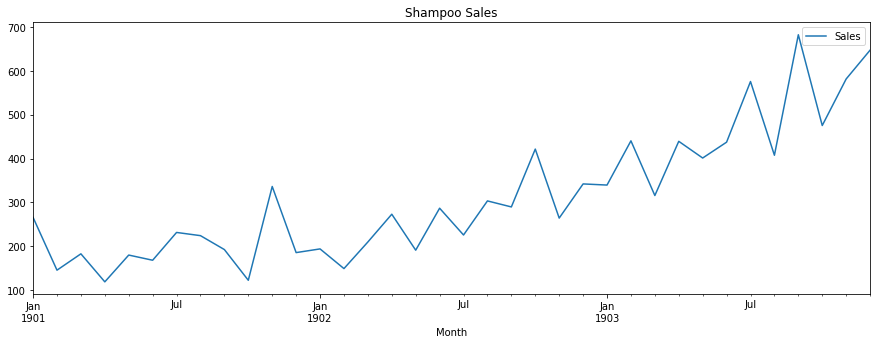

In [21]:
df.plot(figsize=(15,5), title = "Shampoo Sales")
plt.show()

### 1. Detrending mediante diferenciación de la serie

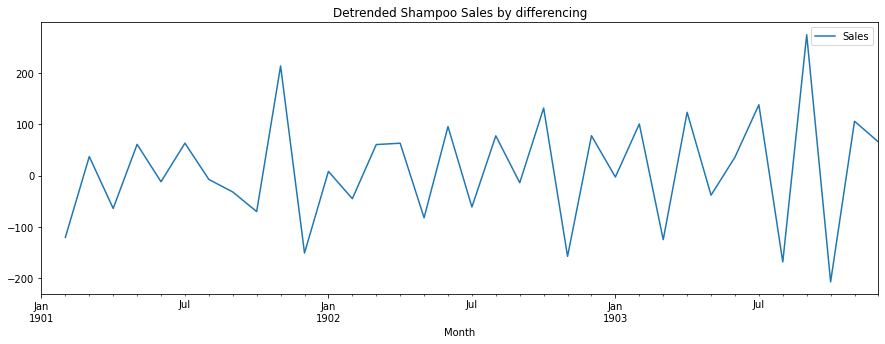

In [56]:
diff = df.diff()
diff.plot(figsize=(15,5), title = "Detrended Shampoo Sales by differencing")
plt.show()

### 2. Detrending mediante eliminación de media móvil

In [37]:
sales = df['Sales'].to_frame()
len(sales)

36

<AxesSubplot:title={'center':'Shampoo Sales with MA'}, xlabel='Month'>

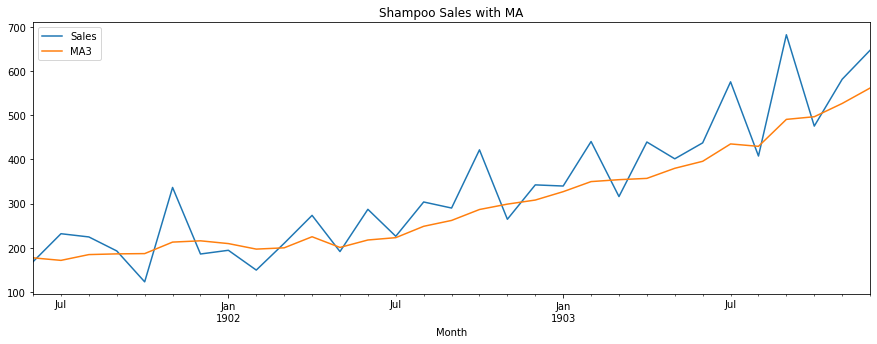

In [38]:
sales['MA3'] = sales['Sales'].rolling(6).mean()
sales.dropna(inplace=True)
sales[['Sales', 'MA3']].plot(title='Shampoo Sales with MA',  figsize=(15, 5))


<AxesSubplot:title={'center':'Detrendend Shampoo Sales by MA'}, xlabel='Month'>

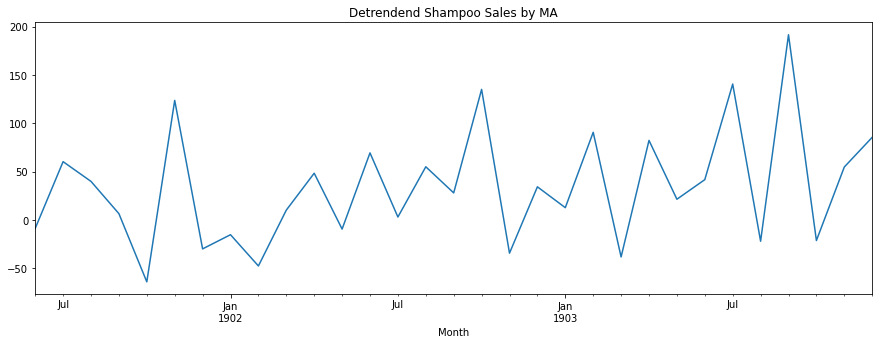

In [55]:
sales["diff"] = sales["Sales"]-sales["MA3"]
sales["diff"].plot(title='Detrendend Shampoo Sales by MA',  figsize=(15, 5))

### 3. Detrending mediante el filtro de Baxter-King
[Link](https://www.statsmodels.org/dev/generated/statsmodels.tsa.filters.bk_filter.bkfilter.html) a la documentación. 
Parámetro de configuración del filtro:
- x: serie temporal que queremos filtrar
- low: Periodo de oscilación mínimo. Se aconseja 6 para datos trimestrales, 1.5 para datos anuales. Como tenemos datos de varios años, le he dado el valor de 1.
- high: Periodo de oscilación máximo. Se aconseja 32 para datos trimestrales, 8 para datos anuales. Como se ve en el ejemplo, he probado varios valores. Se apredia que al aumentar el valor del periodo máximo, aumenta la amplitud de la oscilación. Si podemos el valor a 1, tendremos una línea recta.
- K: Desfase principal a tener en cuenta para el filtro. Se aconseja 12 para datos trimestrales, 3 para datos anuales. Se ha seleccionado 1 para que nos coja toda la serie temporal. Si aumentamos el valor de k, nos filtra un inervalo de la serie temporal menor.

In [6]:
import statsmodels.api as stm

<AxesSubplot:title={'center':'Shampoo Sales with Baxter-King filter'}, xlabel='Month'>

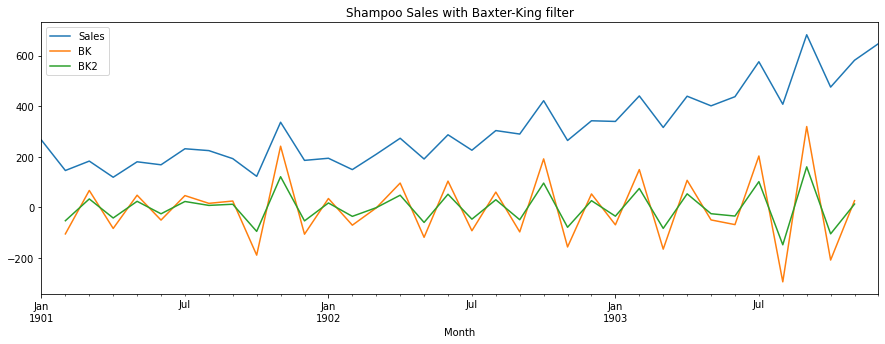

In [91]:
sales2 = df['Sales'].to_frame()
sales2["BK"] = stm.tsa.filters.bkfilter(sales2[['Sales']], 1, 12,1)
sales2["BK2"] = stm.tsa.filters.bkfilter(sales2[['Sales']], 1, 2,1)
sales2[['Sales', 'BK', "BK2"]].plot(title='Shampoo Sales with Baxter-King filter',  figsize=(15, 5))


<AxesSubplot:title={'center':'Detrendend Shampoo Sales by Baxter-King Filter'}, xlabel='Month'>

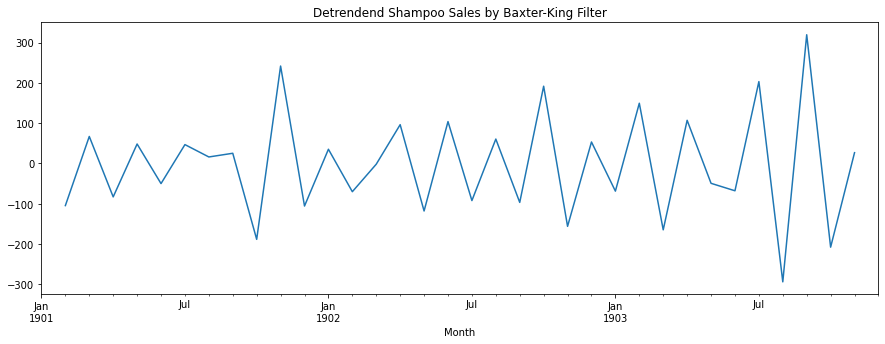

In [54]:
sales2["BK"].plot(title='Detrendend Shampoo Sales by Baxter-King Filter',  figsize=(15, 5))

### 4. Detrending mediante aplicación del filtro de Hodrick-Prescott

<AxesSubplot:title={'center':'Shampoo Sales with Baxter-King filter'}, xlabel='Month'>

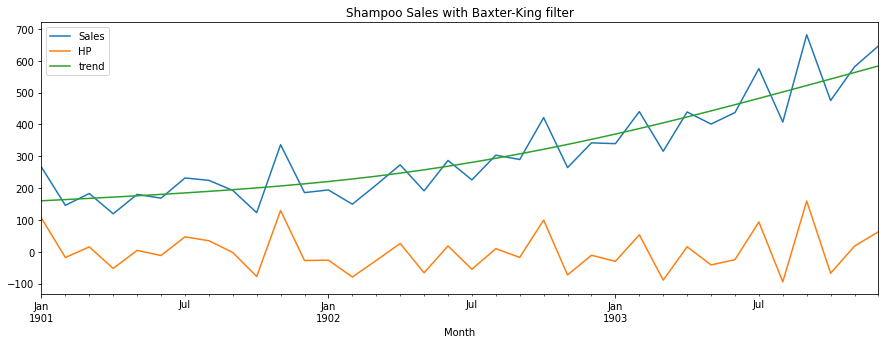

In [63]:
sales3 = df['Sales'].to_frame()
sales3["HP"], sales3["trend"] = stm.tsa.filters.hpfilter(sales3[['Sales']])
sales3[['Sales', 'HP', "trend"]].plot(title='Shampoo Sales with Baxter-King filter',  figsize=(15, 5))


<AxesSubplot:title={'center':'Detrended Shampoo Sales by Hodrick-Prescott filter'}, xlabel='Month'>

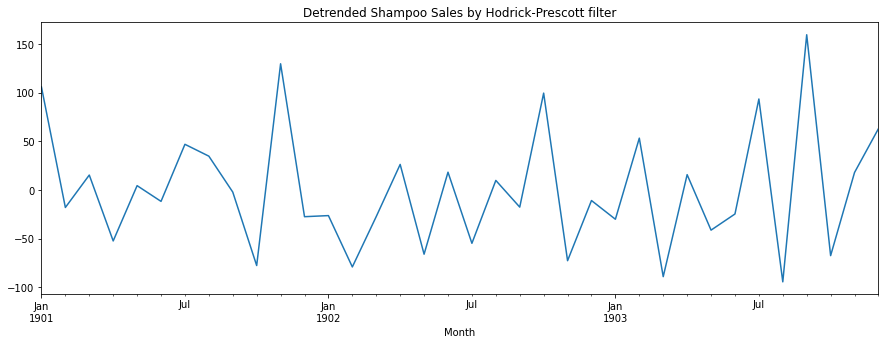

In [64]:
sales3['HP'].plot(title='Detrended Shampoo Sales by Hodrick-Prescott filter',  figsize=(15, 5))


### 5. Detrending meidante seasonal decompose de Statsmodel 

In [57]:
from statsmodels.tsa.seasonal import seasonal_decompose


In [60]:
result = seasonal_decompose(df, model='additive')
trend = result.trend
diff_result = df.Sales.values - trend
diff_result.dropna(inplace=True)

<AxesSubplot:title={'center':'Detrended Shampoo Sales by seasonal decompose'}, xlabel='Month'>

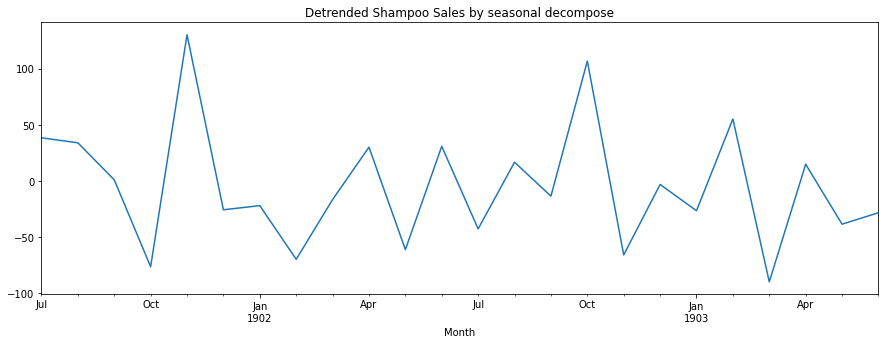

In [61]:
diff_result.plot(title='Detrended Shampoo Sales by seasonal decompose',  figsize=(15, 5))


## Comparación de los resultados

In [85]:
detrended = df.copy()
detrended["diff"] = diff
detrended["MA"] = sales["diff"]
detrended["BK"] = sales2["BK2"]
detrended["HP"] = sales3["HP"]
detrended["SDec"] = diff_result
detrended.drop("Sales", axis=1, inplace=True)

,diff,MA,BK,HP,SDec
Month,,,,,
1901-01-01,NaN,NaN,NaN,105.794569,NaN
1901-02-01,-120.1,NaN,-52.433333,-18.081282,NaN
1901-03-01,37.2,NaN,33.666667,15.276745,NaN
1901-04-01,-63.8,NaN,-41.600000,-52.486170,NaN
1901-05-01,61.0,NaN,24.266667,4.365604,NaN


<AxesSubplot:title={'center':'Detrended Shampoo Sales'}, xlabel='Month'>

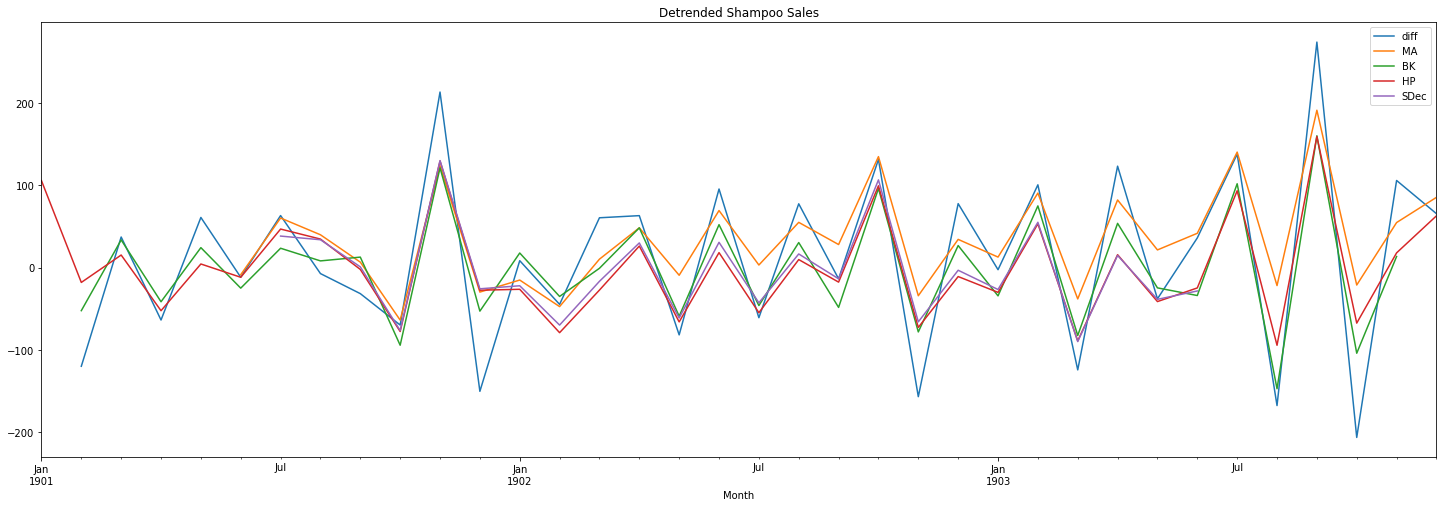

In [86]:
detrended.plot(figsize=(25,8), title = "Detrended Shampoo Sales")